# Notebook 06 - adaptation: how fast does the model recover?
We let the model see a little 2026: add **k** 2026 races to training and test on the rest. Reads `data/model_table.csv.gz` and `results/xgb_params.json`.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.features import encode_features
from f1lap.models import SEED, MODELS, COLORS, PARAMS_PATH, metrics, fit_predict

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df)          # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)

XGB_PARAMS = json.load(open(PARAMS_PATH))

### 1. Few-shot recovery
k = 0, 1, 2, 4, 8. Because early and late 2026 races are at different circuits, we repeat over **5 random race orderings** and report mean +/- spread. Caveat: the test set shrinks as k grows (18 races at k=0 down to 10 at k=8), and the spread partly reflects that.

In [2]:
races_2026 = df.loc[df.season == 2026, 'event'].unique()
K = [0, 1, 2, 4, 8]
rng = np.random.RandomState(SEED)
orderings = [rng.permutation(races_2026) for _ in range(5)]
rows = []
for oi, order in enumerate(orderings):
    for k in K:
        add = set(order[:k]); rest = [r for r in races_2026 if r not in add]
        tr = (df.season < 2026) | ((df.season == 2026) & df.event.isin(add))
        te = (df.season == 2026) & df.event.isin(rest)
        yte = y_all[te].values
        for n in MODELS:
            rows.append({'ordering': oi, 'k': k, 'model': n,
                         'MAE': metrics(yte, fit_predict(n, df, X_all, y_all, tr, te, XGB_PARAMS))['MAE']})
fs = pd.DataFrame(rows)
fs_summary = fs.groupby(['k', 'model']).MAE.agg(['mean', 'std']).reset_index()
print('Mean MAE (s) by k and model:')
fs_summary.pivot(index='k', columns='model', values='mean').round(3)

Mean MAE (s) by k and model:


model,Physics,Residual,XGBoost
k,,,
0,1.137,0.794,0.786
1,1.133,0.755,0.742
2,1.138,0.756,0.744
4,1.144,0.752,0.737
8,1.178,0.770,0.753


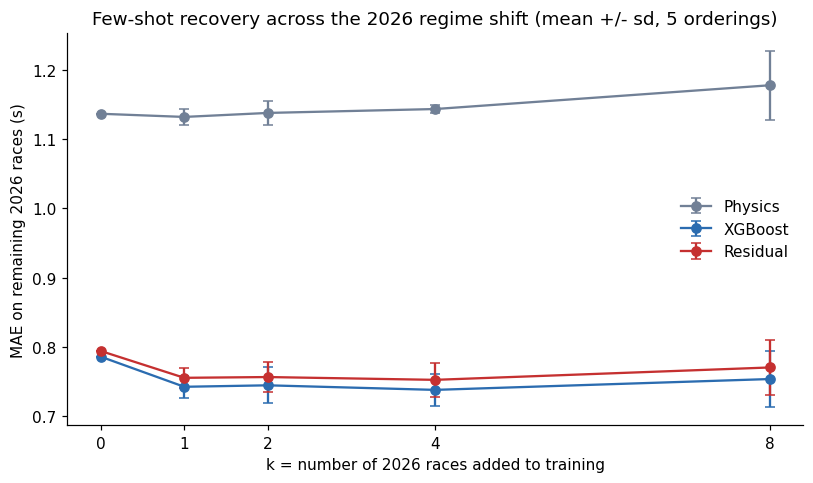

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for n in MODELS:
    s = fs_summary[fs_summary.model == n].sort_values('k')
    ax.errorbar(s.k, s['mean'], yerr=s['std'].fillna(0), marker='o', capsize=3, label=n, color=COLORS[n])
ax.set_xlabel('k = number of 2026 races added to training')
ax.set_ylabel('MAE on remaining 2026 races (s)')
ax.set_title('Few-shot recovery across the 2026 regime shift (mean +/- sd, 5 orderings)')
ax.set_xticks(K); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/06_few_shot_recovery.png', dpi=150); plt.show()

**Figure 06.** Most of the recovery arrives immediately: the first 2026 race drops MAE from **0.79 s (k=0)** to **~0.74 s**, and then the curve flattens, with k = 2, 4, 8 all hovering around **0.74-0.75 s**. A handful of 2026 races gives a quick *partial* fix but does **not** get back to the in-era ~0.59 s bar. The physics baseline barely moves with k, as expected, because its handful of parameters can't absorb new-era structure.